Import Libraries

In [ ]:
!pip install optuna    # Importing optuna that is not in Colaboratory
!pip install catboost  # Importing catboost that is not in Colaboratory

import optuna
import pandas as pd

import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import train_test_split
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

Load Dataset

In [ ]:
df = pd.read_csv('MITArrhythmiaDatabase.csv')

In [ ]:
df.head()

,record,type,0_pre-RR,0_post-RR,0_pPeak,0_tPeak,0_rPeak,0_sPeak,0_qPeak,0_qrs_interval,...,1_qPeak,1_qrs_interval,1_pq_interval,1_qt_interval,1_st_interval,1_qrs_morph0,1_qrs_morph1,1_qrs_morph2,1_qrs_morph3,1_qrs_morph4
0,101,N,76,313.0,0.074347,-0.160548,1.036401,-0.285662,-0.026824,41,...,0.025930,2,18,22,2,0.025930,0.025930,0.025930,0.025436,0.025436
1,101,N,313,315.0,-0.052079,-0.264784,0.886597,-0.366298,-0.059710,21,...,-0.042009,26,27,62,9,-0.042009,-0.029498,0.005012,0.030892,0.002986
2,101,N,315,321.0,-0.062151,-0.296983,0.991859,-0.410306,-0.065686,22,...,0.009528,3,8,12,1,0.009528,0.009528,0.008786,0.008786,0.008368
3,101,N,321,336.0,-0.063322,-0.281386,1.034903,-0.403880,-0.071750,22,...,-0.020536,6,9,16,1,-0.020536,-0.020257,-0.018965,-0.016968,-0.014555
4,101,N,336,344.0,-0.062915,1.046914,1.046408,1.046408,-0.074639,11,...,0.016053,16,5,31,10,0.016053,0.006742,0.002782,-0.007798,-0.051155


Apply Exploratory Data Analysis (EDA)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100689 entries, 0 to 100688
Data columns (total 34 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   record          100689 non-null  int64  
 1   type            100689 non-null  object 
 2   0_pre-RR        100689 non-null  int64  
 3   0_post-RR       100689 non-null  float64
 4   0_pPeak         100689 non-null  float64
 5   0_tPeak         100689 non-null  float64
 6   0_rPeak         100689 non-null  float64
 7   0_sPeak         100689 non-null  float64
 8   0_qPeak         100689 non-null  float64
 9   0_qrs_interval  100689 non-null  int64  
 10  0_pq_interval   100689 non-null  int64  
 11  0_qt_interval   100689 non-null  int64  
 12  0_st_interval   100689 non-null  int64  
 13  0_qrs_morph0    100689 non-null  float64
 14  0_qrs_morph1    100689 non-null  float64
 15  0_qrs_morph2    100689 non-null  float64
 16  0_qrs_morph3    100689 non-null  float64
 17  0_qrs_morp

In [ ]:
print(f'Dataset Shape: {df.shape}\n')

df.describe()

Dataset Shape: (100689, 34)



,record,0_pre-RR,0_post-RR,0_pPeak,0_tPeak,0_rPeak,0_sPeak,0_qPeak,0_qrs_interval,0_pq_interval,...,1_qPeak,1_qrs_interval,1_pq_interval,1_qt_interval,1_st_interval,1_qrs_morph0,1_qrs_morph1,1_qrs_morph2,1_qrs_morph3,1_qrs_morph4
count,100689.000000,100689.000000,100689.000000,100689.000000,100689.000000,100689.000000,100689.000000,100689.000000,100689.000000,100689.000000,...,100689.000000,100689.000000,100689.000000,100689.000000,100689.000000,100689.000000,100689.000000,100689.000000,100689.000000,100689.000000
mean,173.730984,279.400947,278.588207,0.049772,0.372262,1.054485,-0.134376,-0.090466,28.326858,10.972817,...,-0.321359,11.212347,10.487163,36.112922,14.413412,-0.321359,-0.317836,-0.308809,-0.294919,-0.366798
std,51.673158,81.915453,81.124963,0.168789,0.739879,0.617508,1.027590,0.189436,15.027789,9.468930,...,0.447444,12.043096,8.799687,17.419760,9.118872,0.447444,0.456949,0.518043,0.593426,0.584913
min,100.000000,11.000000,6.000000,-3.094391,-2.006422,-2.372835,-3.622550,-3.871359,0.000000,1.000000,...,-5.481982,0.000000,1.000000,5.000000,1.000000,-5.481982,-4.493784,-4.398122,-4.069726,-4.520327
25%,115.000000,230.000000,230.000000,-0.054749,-0.249060,0.754047,-0.781784,-0.133274,18.000000,5.000000,...,-0.529435,3.000000,5.000000,25.000000,10.000000,-0.529435,-0.537288,-0.603469,-0.622269,-0.673902
50%,203.000000,267.000000,266.000000,0.015865,0.240303,1.105142,-0.516340,-0.069539,27.000000,7.000000,...,-0.111843,7.000000,8.000000,33.000000,12.000000,-0.111843,-0.115650,-0.151890,-0.196801,-0.262222
75%,219.000000,324.000000,322.000000,0.125809,0.928176,1.424135,0.857247,-0.014636,38.000000,16.000000,...,-0.028438,18.000000,13.000000,45.000000,17.000000,-0.028438,-0.016348,0.016088,0.040575,-0.052769
max,234.000000,2114.000000,2114.000000,3.821118,4.118327,4.018918,4.018918,3.080710,170.000000,150.000000,...,4.033554,260.000000,185.000000,412.000000,215.000000,4.033554,3.585718,2.691557,3.755566,2.869186


In [ ]:
print(df.isnull().sum())

record            0
type              0
0_pre-RR          0
0_post-RR         0
0_pPeak           0
0_tPeak           0
0_rPeak           0
0_sPeak           0
0_qPeak           0
0_qrs_interval    0
0_pq_interval     0
0_qt_interval     0
0_st_interval     0
0_qrs_morph0      0
0_qrs_morph1      0
0_qrs_morph2      0
0_qrs_morph3      0
0_qrs_morph4      0
1_pre-RR          0
1_post-RR         0
1_pPeak           0
1_tPeak           0
1_rPeak           0
1_sPeak           0
1_qPeak           0
1_qrs_interval    0
1_pq_interval     0
1_qt_interval     0
1_st_interval     0
1_qrs_morph0      0
1_qrs_morph1      0
1_qrs_morph2      0
1_qrs_morph3      0
1_qrs_morph4      0
dtype: int64


In [ ]:
print(df['type'].value_counts())

type
N       90083
VEB      7009
SVEB     2779
F         803
Q          15
Name: count, dtype: int64


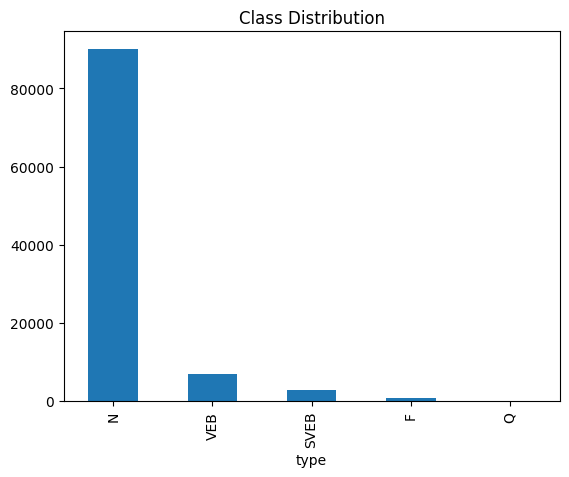

In [ ]:
df['type'].value_counts().plot(kind='bar', title='Class Distribution')
plt.show()

In [ ]:
df = df[df['type'] != 'Q']   #Removing Q because there is just a few ???? (NOT SURE)

15 examples are not enough for the model to learn.

It disrupts the class balance, the model gives incorrect results.

If you try to do SMOTE, you may get a k_neighbors error.

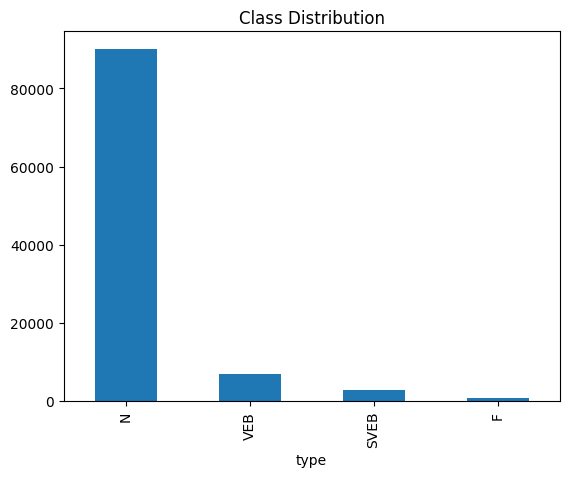

In [ ]:
df['type'].value_counts().plot(kind='bar', title='Class Distribution')
plt.show()   #Class Distribution without Q

Data Preprocessing

In [ ]:
label_encoder = LabelEncoder()   #Encode Labels
df['type'] = label_encoder.fit_transform(df['type'])

In [ ]:
print(dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_))))

{'F': np.int64(0), 'N': np.int64(1), 'SVEB': np.int64(2), 'VEB': np.int64(3)}


In [ ]:
X = df.drop(['record', 'type'], axis=1)   #Features and Target
y = df['type']

In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)  # Split into Train, Validation, and Test Sets
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)

PCA (Principal Component Analysis)

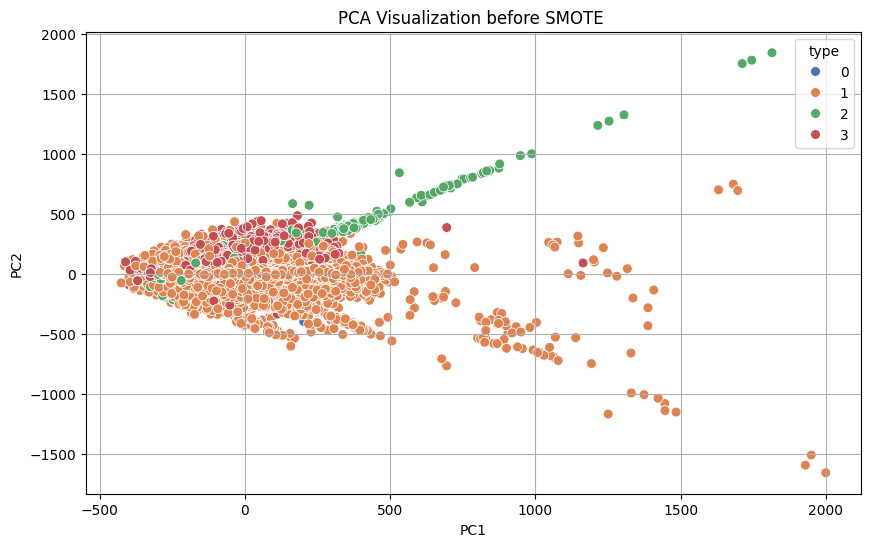

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# Take the features
X = df.drop(['record', 'type'], axis=1)
y = df['type']


# PCA
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train)

# DataFrame building
pca_df = pd.DataFrame(X_train_pca, columns=["PC1", "PC2"])
pca_df["type"] = y_train.values

# Plotle
plt.figure(figsize=(10, 6))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="type", palette="deep", s=50)
plt.title("PCA Visualization before SMOTE ")
plt.grid(True)
plt.show()


Apply NORMAL SMOTE

In [ ]:
# Apply SMOTE only to train data
from imblearn.over_sampling import SMOTE

smote = SMOTE(sampling_strategy='not majority', random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)


Compare after SMOTE

In [ ]:
# PCA
X_res_pca = pca.transform(X_train_resampled)

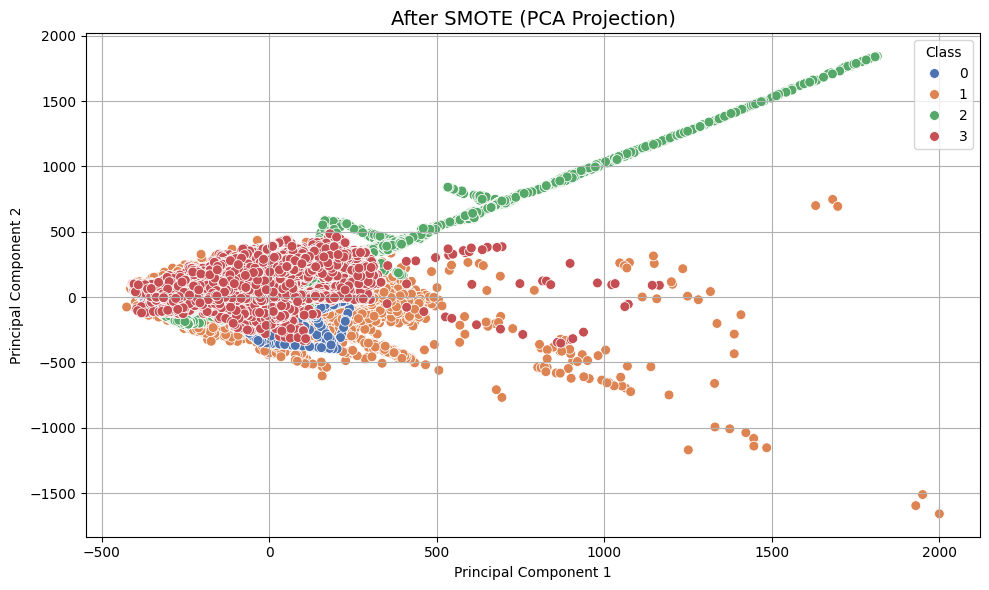

In [ ]:
# Build dataframes to visualize

df_after = pd.DataFrame(X_res_pca, columns=["PC1", "PC2"])
df_after["Class"] = y_train_resampled.values

# Drawing
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_after, x="PC1", y="PC2", hue="Class", palette="deep", s=50)
plt.title("After SMOTE (PCA Projection)", fontsize=14)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True)
plt.legend(title="Class")
plt.tight_layout()
plt.show()

In [ ]:
pd.Series(y_train_resampled).value_counts() #Controlling the class distribution numerically

,count
type,
1,63058
3,63058
2,63058
0,63058


In [ ]:
pd.Series(y_train).value_counts()

,count
type,
1,63058
3,4906
2,1945
0,562


In [ ]:
import matplotlib.pyplot as plt
from collections import Counter
import pandas as pd

In [ ]:
# before Smote
before_counts = Counter(y_train)

# after Smote
after_counts = Counter(y_train_resampled)


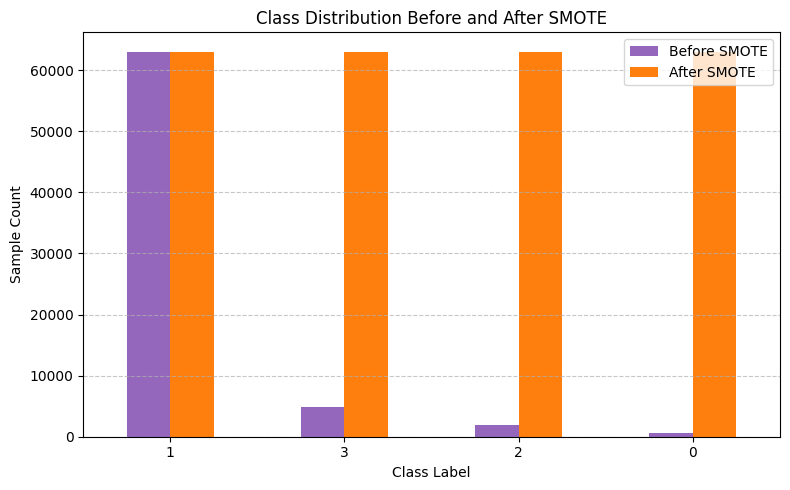

In [ ]:
# Change to Pandas DataFrame
df_before = pd.DataFrame.from_dict(before_counts, orient='index', columns=['Before SMOTE'])
df_after = pd.DataFrame.from_dict(after_counts, orient='index', columns=['After SMOTE'])

# Combine
df_compare = pd.concat([df_before, df_after], axis=1).fillna(0).astype(int)
df_compare.index.name = 'Class'

# Draw
df_compare.plot(kind='bar', figsize=(8, 5), rot=0,color=['#9467bd', '#ff7f0e'])
plt.title('Class Distribution Before and After SMOTE')
plt.ylabel('Sample Count')
plt.xlabel('Class Label')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


Try another SMOTE Technique (SMOTEENN)

In [ ]:
from imblearn.combine import SMOTEENN
from collections import Counter

smote_enn = SMOTEENN(random_state=42)
X_train_resampled_smoteenn, y_train_resampled_smoteenn = smote_enn.fit_resample(X_train, y_train)

print("After smote:", Counter(y_train_resampled_smoteenn))

Dağılım sonrası: Counter({0: 63004, 2: 62853, 3: 62784, 1: 59209})


Apply XGB MODEL

Import Libraries

In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix

Initialize the Model and Train it

In [ ]:
# #Define the Model
# xgb_model = XGBClassifier(use_label_encoder=False, eval_metric='mlogloss', random_state=42)

# #Train the model with the data after smote
# xgb_model.fit(X_train_resampled, y_train_resampled)


XGBoost Model Training with Early Stopping to Reduce Overfitting

 Early Stopping: Model eğitimi sırasında overfitting’e karşı fren

In [ ]:
#Try max_depth=4, add early stopping, increase reg_lambda ve reg_alpha to prevent overfitting
xgb_model = XGBClassifier(
    max_depth=4,
    reg_lambda=2.0,
    reg_alpha=1.0,
    use_label_encoder=False,
    eval_metric='mlogloss',
    random_state=42,
    early_stopping_rounds=20
)

xgb_model.fit(
    X_train_resampled_smoteenn, y_train_resampled_smoteenn,
    eval_set=[(X_val, y_val)],
    verbose=False
)


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [10:12:56] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=20,
              enable_categorical=False, eval_metric='mlogloss',
              feature_types=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, objective='multi:softprob', ...)

Prediction with Test Set

In [ ]:
# Do the prediction
y_pred = xgb_model.predict(X_test)

Apply Threshold Tuning

In [ ]:
# 2. Get probability estimate (predict_proba)
y_proba = xgb_model.predict_proba(X_test)

In [ ]:
# 3. Generate custom predictions based on threshold
thresholds = {
    0: 0.75,
    2: 0.75,
    3: 0.75
}

In [ ]:
import numpy as np

def predict_with_thresholds(y_proba, thresholds, fallback_class=1):
    preds = []
    for prob in y_proba:
        if prob[0] >= thresholds.get(0, 1.1):
            preds.append(0)
        elif prob[2] >= thresholds.get(2, 1.1):
            preds.append(2)
        elif prob[3] >= thresholds.get(3, 1.1):
            preds.append(3)
        else:
            preds.append(fallback_class)
    return preds


In [ ]:
y_pred_thresh = predict_with_thresholds(xgb_model.predict_proba(X_test), thresholds)

Evaluate the Performance

Classification Report Test Set:

              precision    recall  f1-score   support

           0       0.87      0.86      0.87       120
           1       0.99      0.99      0.99     13513
           2       0.79      0.90      0.84       417
           3       0.96      0.96      0.96      1052

    accuracy                           0.98     15102
   macro avg       0.90      0.93      0.92     15102
weighted avg       0.98      0.98      0.98     15102



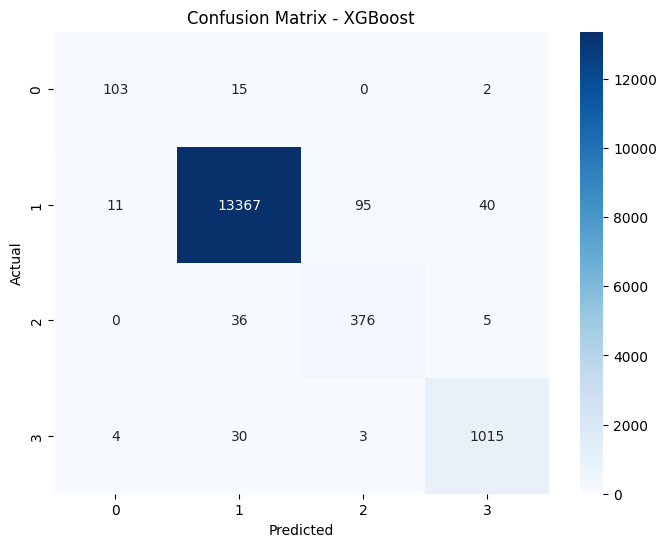

In [ ]:
# Performance Report
print("Classification Report Test Set:\n")
print(classification_report(y_test, y_pred_thresh))

# Confusion Matrix
import seaborn as sns
import matplotlib.pyplot as plt
cm = confusion_matrix(y_test, y_pred_thresh)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=xgb_model.classes_, yticklabels=xgb_model.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - XGBoost')
plt.show()

Feature Importances Visualization

<ipython-input-31-3692780215>:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance_df.head(20), x='Importance', y='Feature', palette='viridis')


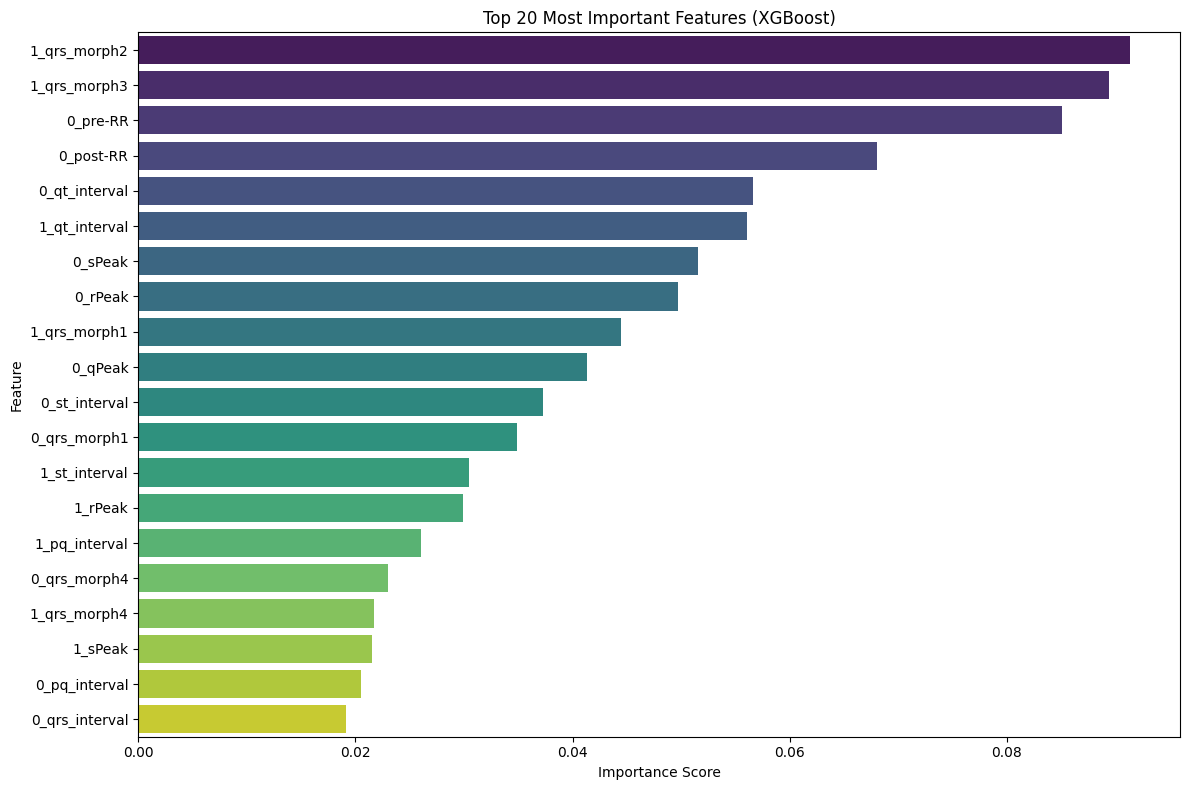

In [ ]:
# Feature names (must be in the same order as X_train_resampled!)
feature_names = X_train_resampled.columns

# Dump importance values ​​to DataFrame
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': xgb_model.feature_importances_
})

# Sort by importance
importance_df = importance_df.sort_values(by='Importance', ascending=False)

# Visualize
plt.figure(figsize=(12, 8))
sns.barplot(data=importance_df.head(20), x='Importance', y='Feature', palette='viridis')
plt.title('Top 20 Most Important Features (XGBoost)')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()


See  Train Set Performance

In [ ]:
from sklearn.metrics import classification_report

print("Classification Report Train Set:\n")
y_train_pred = xgb_model.predict(X_train_resampled_smoteenn)
print(classification_report(y_train_resampled_smoteenn, y_train_pred))


Classification Report Train Set:

              precision    recall  f1-score   support

           0       0.99      1.00      1.00     63004
           1       1.00      0.99      0.99     59209
           2       0.99      1.00      1.00     62853
           3       1.00      0.99      1.00     62784

    accuracy                           1.00    247850
   macro avg       1.00      1.00      1.00    247850
weighted avg       1.00      1.00      1.00    247850



Apply Cross Validation to check Overfitting (For the model training without early stopping)

In [ ]:
# from sklearn.model_selection import cross_val_score
# from sklearn.metrics import make_scorer, f1_score
# import numpy as np

# # Çok sınıflı F1 skoru için scorer tanımla
# f1_macro_scorer = make_scorer(f1_score, average='macro')

# # Cross-validation (5-fold)
# cv_scores = cross_val_score(
#     xgb_model,
#     X_train_resampled,
#     y_train_resampled,
#     cv=5,
#     scoring=f1_macro_scorer,
#     n_jobs=-1,  # paralel çalıştırmak için
#     error_score='raise'  # bu satırı ekle!
# )

# # Sonuçları yazdır
# print("F1 Macro Scores for each fold:", np.round(cv_scores, 4))
# print("Mean F1 Macro:", np.round(cv_scores.mean(), 4))
# print("Std Deviation:", np.round(cv_scores.std(), 4))


Apply Stratified K-Fold with Early Stopping to check Overfitting (For the model training with early stopping)

In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score
import numpy as np

kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = []

for fold, (train_idx, val_idx) in enumerate(kf.split(X_train_resampled, y_train_resampled)):
    X_tr = X_train_resampled.iloc[train_idx]
    X_val = X_train_resampled.iloc[val_idx]
    y_tr = y_train_resampled.iloc[train_idx]
    y_val = y_train_resampled.iloc[val_idx]


    model = XGBClassifier(
        max_depth=4,
        learning_rate=0.1,
        n_estimators=500,
        reg_lambda=2.0,
        reg_alpha=1.0,
        subsample=0.8,
        colsample_bytree=0.8,
        gamma=2.0,
        eval_metric="mlogloss",
        random_state=fold,  # different for each fold
        early_stopping_rounds=20
    )

    model.fit(
        X_tr, y_tr,
        eval_set=[(X_val, y_val)],
        verbose=False
    )

    preds = model.predict(X_val)
    f1 = f1_score(y_val, preds, average='macro')
    scores.append(f1)
    print(f"Fold {fold+1} F1 Macro: {round(f1, 4)}")

print("\nAverage F1 Macro:", round(np.mean(scores), 4))
print("Std Dev:", round(np.std(scores), 4))


Fold 1 F1 Macro: 0.9923
Fold 2 F1 Macro: 0.9922
Fold 3 F1 Macro: 0.993
Fold 4 F1 Macro: 0.9931
Fold 5 F1 Macro: 0.9922

Average F1 Macro: 0.9926
Std Dev: 0.0004


XGBoost AUC Scores (One-vs-Rest method)

In [ ]:
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import label_binarize

# Sınıfları binarize et (One-vs-Rest için)
y_test_bin = label_binarize(y_test, classes=[0, 1, 2, 3])
y_proba = xgb_model.predict_proba(X_test)

# Multi-class AUC (OvR)
auc_macro = roc_auc_score(y_test_bin, y_proba, average='macro', multi_class='ovr')
auc_weighted = roc_auc_score(y_test_bin, y_proba, average='weighted', multi_class='ovr')

print("XGBoost AUC (Macro):", round(auc_macro, 4))
print("XGBoost AUC (Weighted):", round(auc_weighted, 4))


XGBoost AUC (Macro): 0.9951
XGBoost AUC (Weighted): 0.9974


LightGBM Model

Import Libraries

In [ ]:
from lightgbm import LGBMClassifier
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

Define Model

In [ ]:
# Define the LightGBM model
lgb_model = LGBMClassifier(random_state=42)

# Train with the data after smote
lgb_model.fit(X_train_resampled, y_train_resampled)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.089098 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 7383
[LightGBM] [Info] Number of data points in the train set: 252232, number of used features: 32
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294


LGBMClassifier(random_state=42)

In [ ]:
# Apply prediction on test data
y_pred_lgb = lgb_model.predict(X_test)

Performance Results

Classification Report (LightGBM):

              precision    recall  f1-score   support

           0       0.81      0.91      0.86       120
           1       1.00      0.99      0.99     13513
           2       0.83      0.93      0.88       417
           3       0.95      0.98      0.96      1052

    accuracy                           0.99     15102
   macro avg       0.90      0.95      0.92     15102
weighted avg       0.99      0.99      0.99     15102



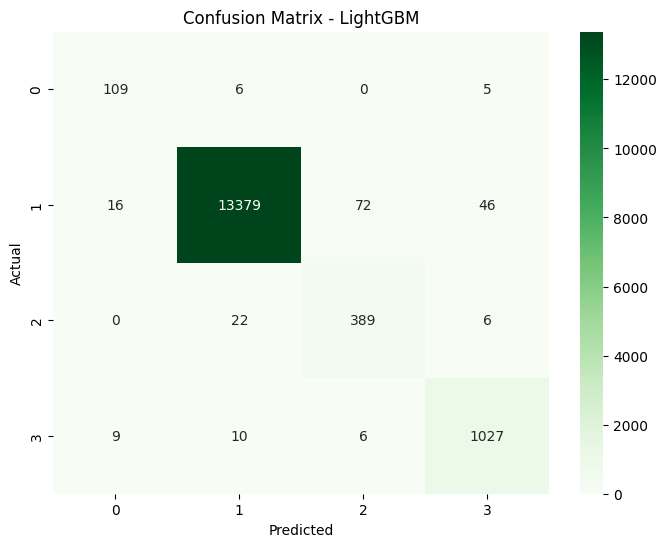

In [ ]:
# Classification report
print("Classification Report (LightGBM):\n")
print(classification_report(y_test, y_pred_lgb))

# Confusion matrix
cm_lgb = confusion_matrix(y_test, y_pred_lgb)

plt.figure(figsize=(8,6))
sns.heatmap(cm_lgb, annot=True, fmt='d', cmap='Greens', xticklabels=lgb_model.classes_, yticklabels=lgb_model.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - LightGBM')
plt.show()


Check Overfitting with Train Data

In [ ]:
from sklearn.metrics import classification_report

y_train_pred = lgb_model.predict(X_train_resampled)
print(classification_report(y_train_resampled, y_train_pred))



              precision    recall  f1-score   support

           0       1.00      1.00      1.00     63058
           1       1.00      0.99      1.00     63058
           2       1.00      1.00      1.00     63058
           3       1.00      1.00      1.00     63058

    accuracy                           1.00    252232
   macro avg       1.00      1.00      1.00    252232
weighted avg       1.00      1.00      1.00    252232



%100 success — In all the classes precision, recall ve F1-score = 1.00
There is small overfitting

Apply Different SMOTE to Prevent Overfitting

In [ ]:
from collections import Counter
print("y_train distribution before SMOTE:", Counter(y_train))


y_train distribution before SMOTE: Counter({1: 63058, 3: 4906, 2: 1945, 0: 562})


In [ ]:
# You can reconfigure the instantiation based on class
smote = SMOTE(sampling_strategy={
    0: 1500,  # available: 562
    2: 3000   # available: 1945
    # class 3 is already 4906 → less cannot be requested
}, random_state=42)


X_train_resampled2, y_train_resampled2 = smote.fit_resample(X_train, y_train)

    0: 2000, 2: 5000, 3: 5000 tried these values but there were still a little overfitting.
    
     




Train the model with LightGBM again

In [ ]:
lgb_model = LGBMClassifier(class_weight='balanced', random_state=42)
lgb_model.fit(X_train_resampled2, y_train_resampled2)


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.017470 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 7196
[LightGBM] [Info] Number of data points in the train set: 72464, number of used features: 32
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294


LGBMClassifier(class_weight='balanced', random_state=42)

Evaluate Test Set

Classification Report:

              precision    recall  f1-score   support

           0       0.87      0.89      0.88       120
           1       1.00      0.99      0.99     13513
           2       0.85      0.92      0.89       417
           3       0.96      0.98      0.97      1052

    accuracy                           0.99     15102
   macro avg       0.92      0.95      0.93     15102
weighted avg       0.99      0.99      0.99     15102



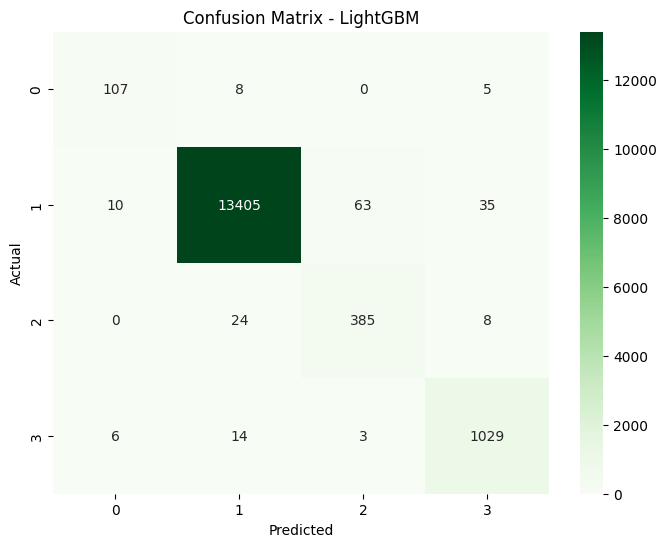

In [ ]:
y_pred = lgb_model.predict(X_test)

print("Classification Report:\n")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=lgb_model.classes_, yticklabels=lgb_model.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - LightGBM")
plt.show()


Check Train Set Performance Again with new Smote Technique

In [ ]:
from sklearn.metrics import classification_report

y_train_pred = lgb_model.predict(X_train_resampled2)
print(classification_report(y_train_resampled2, y_train_pred))


              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1500
           1       1.00      0.99      1.00     63058
           2       0.93      1.00      0.96      3000
           3       0.98      1.00      0.99      4906

    accuracy                           1.00     72464
   macro avg       0.97      1.00      0.99     72464
weighted avg       1.00      1.00      1.00     72464



| Class     | F1 Difference (Train - Test) |
| --------- | ----------------------- |
| 0         | **0.99 - 0.88 = 0.11**  |
| 2         | **0.96 - 0.89 = 0.07**  |
| **Macro** | **0.99 - 0.93 = 0.06**  |

Overfitting is reduced. For class 0, F1 difference is 0.11 → acceptable


Check Performance with Stratified K-Fold cross-validation

In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score
import numpy as np
from lightgbm import LGBMClassifier, early_stopping

kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = []

for fold, (train_idx, val_idx) in enumerate(kf.split(X_train_resampled2, y_train_resampled2)):
    X_tr = X_train_resampled2.iloc[train_idx]
    X_val = X_train_resampled2.iloc[val_idx]
    y_tr = y_train_resampled2.iloc[train_idx]
    y_val = y_train_resampled2.iloc[val_idx]

    model = LGBMClassifier(
        class_weight='balanced',
        random_state=42,
        n_estimators=500,
        learning_rate=0.05,
        num_leaves=31,
        subsample=0.8,
        colsample_bytree=0.8
    )

    model.fit(
        X_tr, y_tr,
        eval_set=[(X_val, y_val)],
        eval_metric='multi_logloss',
        callbacks=[early_stopping(stopping_rounds=20, verbose=False)]
    )

    preds = model.predict(X_val)
    f1 = f1_score(y_val, preds, average='macro')
    scores.append(f1)
    print(f"Fold {fold+1} F1 Macro: {round(f1, 4)}")

print("\n✅ Average F1 Macro:", round(np.mean(scores), 4))
print("📉 Std Dev:", round(np.std(scores), 4))


Fold 1 F1 Macro: 0.9727
Fold 2 F1 Macro: 0.9633
Fold 3 F1 Macro: 0.9649
Fold 4 F1 Macro: 0.9673
Fold 5 F1 Macro: 0.9652

✅ Average F1 Macro: 0.9667
📉 Std Dev: 0.0033


 AUC Scores (macro and weighted)

In [ ]:
y_test_bin = label_binarize(y_test, classes=lgb_model.classes_)
y_proba_lgb = lgb_model.predict_proba(X_test)

auc_macro = roc_auc_score(y_test_bin, y_proba_lgb, average="macro", multi_class="ovr")
auc_weighted = roc_auc_score(y_test_bin, y_proba_lgb, average="weighted", multi_class="ovr")

print("LightGBM AUC (Macro):", round(auc_macro, 4))
print("LightGBM AUC (Weighted):", round(auc_weighted, 4))


LightGBM AUC (Macro): 0.996
LightGBM AUC (Weighted): 0.9984


ELASTICNET (LOGISTIC REGRESSION) MODEL

Import Libraries

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

Define the Model And Train it

In [ ]:
elasticnet_model = Pipeline([
    ("scaler", StandardScaler()),  # Normalize features, it is mandatory for elastic net!
    ("classifier", LogisticRegression(
        penalty='elasticnet',
        solver='saga',         # Mandatory solver for ElasticNet
        l1_ratio=0.5,          # 0 = L2, 1 = L1; 0.5 = equal mixing
        max_iter=5000,
        multi_class='multinomial',
        random_state=42
    ))
])

elasticnet_model.fit(X_train_resampled, y_train_resampled)


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(l1_ratio=0.5, max_iter=5000,
                                    multi_class='multinomial',
                                    penalty='elasticnet', random_state=42,
                                    solver='saga'))])

Look at the Performance (On Test Set)

Classification Report - ElasticNet Logistic Regression:

              precision    recall  f1-score   support

           0       0.23      0.72      0.34       120
           1       0.98      0.93      0.95     13513
           2       0.32      0.70      0.44       417
           3       0.81      0.81      0.81      1052

    accuracy                           0.91     15102
   macro avg       0.58      0.79      0.64     15102
weighted avg       0.94      0.91      0.92     15102



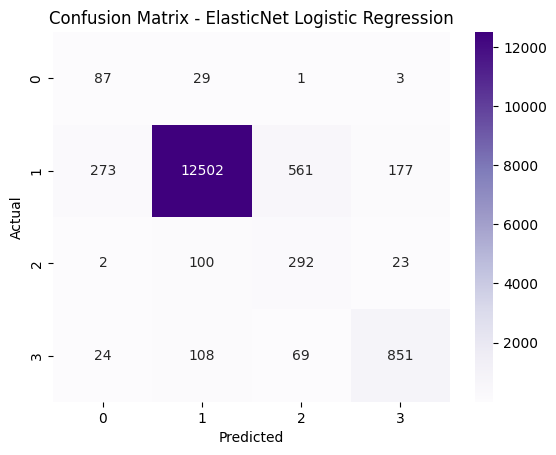

In [ ]:
y_pred_enet = elasticnet_model.predict(X_test)

print("Classification Report - ElasticNet Logistic Regression:\n")
print(classification_report(y_test, y_pred_enet))

cm = confusion_matrix(y_test, y_pred_enet)
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples',
            xticklabels=elasticnet_model.classes_,
            yticklabels=elasticnet_model.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - ElasticNet Logistic Regression")
plt.show()

Look at the Performance (On Train Set) to check Overfitting

In [ ]:
y_train_pred_enet = elasticnet_model.predict(X_train_resampled)
print("Train Report - ElasticNet:\n")
print(classification_report(y_train_resampled, y_train_pred_enet))

Train Report - ElasticNet:

              precision    recall  f1-score   support

           0       0.90      0.90      0.90     63058
           1       0.90      0.92      0.91     63058
           2       0.86      0.87      0.86     63058
           3       0.90      0.87      0.89     63058

    accuracy                           0.89    252232
   macro avg       0.89      0.89      0.89    252232
weighted avg       0.89      0.89      0.89    252232



Fast GridSearchCV – ElasticNet (Logistic Regression)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

# define Pipeline
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        penalty='elasticnet',
        solver='saga',
        max_iter=1000,
        multi_class='multinomial',
        random_state=42
    ))
])

# Small parameter grid (fast result)
param_grid = {
    "classifier__C": [0.1, 1.0],             # just 2 values
    "classifier__l1_ratio": [0.3, 0.7],       # Middle level l1-l2 balance
    "classifier__class_weight": [None, "balanced"]
}

# define GridSearchCV
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=3,                    # 3 fold = faster
    verbose=1,
    n_jobs=-1                # use all
)

# Eğitim
grid_search.fit(X_train_resampled, y_train_resampled)


Fitting 3 folds for each of 8 candidates, totalling 24 fits


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


GridSearchCV(cv=3,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('classifier',
                                        LogisticRegression(max_iter=1000,
                                                           multi_class='multinomial',
                                                           penalty='elasticnet',
                                                           random_state=42,
                                                           solver='saga'))]),
             n_jobs=-1,
             param_grid={'classifier__C': [0.1, 1.0],
                         'classifier__class_weight': [None, 'balanced'],
                         'classifier__l1_ratio': [0.3, 0.7]},
             scoring='f1_macro', verbose=1)

In [ ]:
print("Best Params:", grid_search.best_params_)
print("Best Score (CV F1 Macro):", round(grid_search.best_score_, 4))


Best Params: {'classifier__C': 1.0, 'classifier__class_weight': None, 'classifier__l1_ratio': 0.7}
Best Score (CV F1 Macro): 0.889


 Final Model with Best Parameters

Classification Report - Final ElasticNet:

              precision    recall  f1-score   support

           0       0.23      0.70      0.35       120
           1       0.98      0.93      0.95     13513
           2       0.33      0.69      0.44       417
           3       0.81      0.81      0.81      1052

    accuracy                           0.91     15102
   macro avg       0.59      0.78      0.64     15102
weighted avg       0.94      0.91      0.93     15102



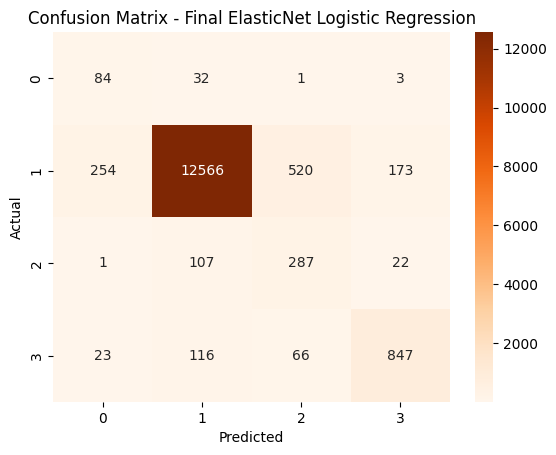

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Final model
final_elastic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        penalty='elasticnet',
        solver='saga',
        l1_ratio=0.7,
        C=1.0,
        max_iter=5000,
        random_state=42
    ))
])

# Train
final_elastic_model.fit(X_train_resampled, y_train_resampled)

# Predict on Test set
y_pred_final = final_elastic_model.predict(X_test)

# Report
print("Classification Report - Final ElasticNet:\n")
print(classification_report(y_test, y_pred_final))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_final)
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=final_elastic_model.classes_,
            yticklabels=final_elastic_model.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Final ElasticNet Logistic Regression")
plt.show()


ElasticNet model is inadequate for this problem.
Stronger models perform significantly better.

AUC Scores for ElasticNet

In [ ]:
# Get probability estimates for the test set
y_proba_final = final_elastic_model.predict_proba(X_test)

# Calculate AUC scores
auc_macro = roc_auc_score(y_test, y_proba_final, average='macro', multi_class='ovr')
auc_weighted = roc_auc_score(y_test, y_proba_final, average='weighted', multi_class='ovr')

print(f"ElasticNet AUC (Macro): {round(auc_macro, 4)}")
print(f"ElasticNet AUC (Weighted): {round(auc_weighted, 4)}")


ElasticNet AUC (Macro): 0.9593
ElasticNet AUC (Weighted): 0.9589


MODEL SELECTION

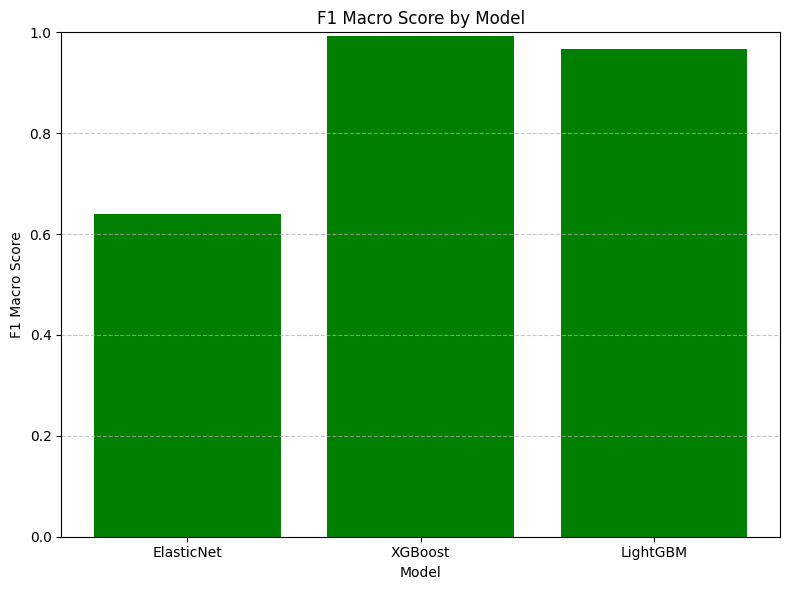

In [ ]:
import matplotlib.pyplot as plt

# Model isimleri ve skorlar
models = ["ElasticNet", "XGBoost", "LightGBM"]
f1_scores = [0.64, 0.9926, 0.9667]

# Color
colors = ["green"]

# Graph
plt.figure(figsize=(8, 6))
plt.bar(models, f1_scores, color=colors)
plt.ylim(0, 1)
plt.title("F1 Macro Score by Model")
plt.ylabel("F1 Macro Score")
plt.xlabel("Model")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


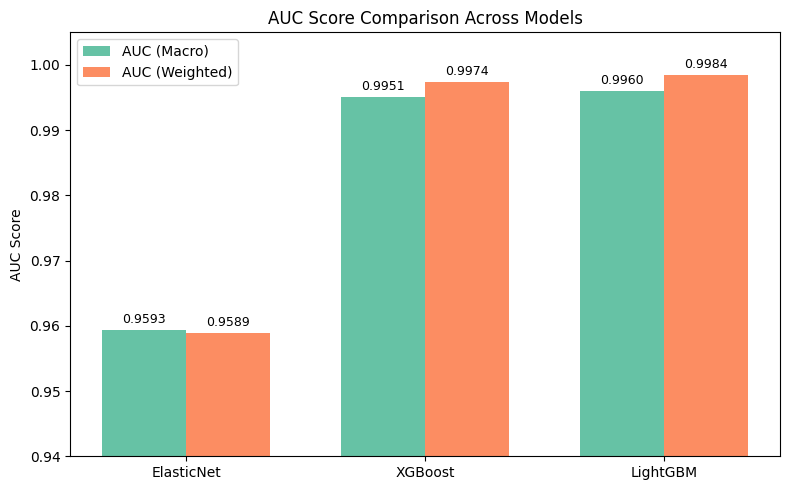

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Models and AUC values
models = ["ElasticNet", "XGBoost", "LightGBM"]
auc_macro = [0.9593, 0.9951, 0.9960]
auc_weighted = [0.9589, 0.9974, 0.9984]

x = np.arange(len(models))  # for X
width = 0.35  # Bar width

# graph
fig, ax = plt.subplots(figsize=(8, 5))

bars1 = ax.bar(x - width/2, auc_macro, width, label='AUC (Macro)', color='#66c2a5')
bars2 = ax.bar(x + width/2, auc_weighted, width, label='AUC (Weighted)', color='#fc8d62')

# Writings
ax.set_ylabel('AUC Score')
ax.set_title('AUC Score Comparison Across Models')
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(0.94, 1.005)
ax.legend()

# For each bar
def add_labels(bars):
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.4f}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),  # Yukarıya 3 birim offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9)

add_labels(bars1)
add_labels(bars2)

plt.tight_layout()
plt.show()
